In [1]:
!pip install shap

In [2]:
import kagglehub
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import os
import shap
from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet121
from sklearn.metrics import confusion_matrix, f1_score, recall_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

In [3]:
DATASET_PATH = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", DATASET_PATH)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [4]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

base_dir = os.path.join(DATASET_PATH, "chest_xray")

train_dir = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'test')

print("\nConjunto de Treino (train):")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=True
)

print("\nConjunto de Validação (val):")
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=False
)

class_names = train_dataset.class_names
print(f"\nClasses identificadas: {class_names}")


Conjunto de Treino (train):
Found 5216 files belonging to 2 classes.

Conjunto de Validação (val):
Found 624 files belonging to 2 classes.

Classes identificadas: ['NORMAL', 'PNEUMONIA']


In [5]:
def normalize(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_dataset = train_dataset.map(normalize)
validation_dataset = validation_dataset.map(normalize)

print("Dados normalizados com sucesso!")

Dados normalizados com sucesso!


In [6]:
y_train = np.concatenate([y.numpy() for x, y in train_dataset], axis=0).flatten()

classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights_dict = {int(c): float(w) for c, w in zip(classes, weights)}

print("Pesos calculados para as classes:", class_weights_dict)

Pesos calculados para as classes: {0: 1.9448173005219984, 1: 0.6730322580645162}


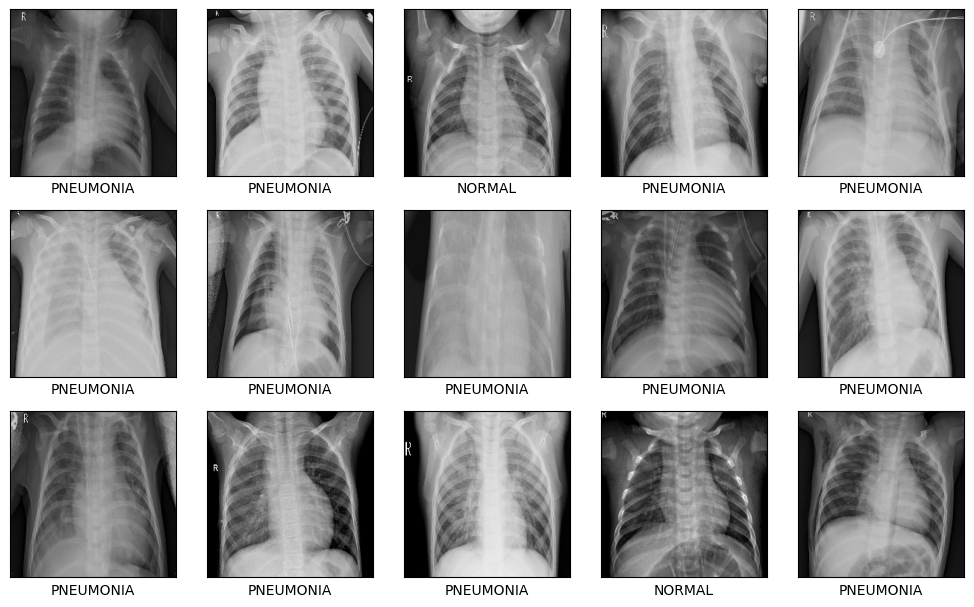

In [7]:
for images_batch, labels_batch in train_dataset.take(1):
    plt.figure(figsize=(10, 10))
    for i in range(min(15, len(images_batch))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.imshow(images_batch[i].numpy())
        label_idx = int(labels_batch[i].numpy()[0])
        plt.xlabel(class_names[label_idx])
    plt.tight_layout()
    plt.show()

In [8]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.05),
], name="data_augmentation")

base_model = DenseNet121(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    include_top=False,
    weights='imagenet'
)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [9]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    data_augmentation,
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001)),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001)),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,332,929 (27.97 MB)

 Trainable params: 936,833 (3.57 MB)

 Non-trainable params: 6,396,096 (24.40 MB)

In [10]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001), loss='binary_crossentropy', metrics=['accuracy'])

In [11]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(train_dataset, validation_data=validation_dataset, epochs=50, callbacks=[early_stopping], class_weight=class_weights_dict)

Epoch 1/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 74s 317ms/step - accuracy: 0.5339 - loss: 1.3503 - val_accuracy: 0.6522 - val_loss: 1.1820
Epoch 2/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 50s 305ms/step - accuracy: 0.6655 - loss: 1.1674 - val_accuracy: 0.8269 - val_loss: 1.0033
Epoch 3/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 37s 224ms/step - accuracy: 0.7584 - loss: 1.0371 - val_accuracy: 0.8622 - val_loss: 0.9180
Epoch 4/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 38s 231ms/step - accuracy: 0.8265 - loss: 0.9324 - val_accuracy: 0.8782 - val_loss: 0.8577
Epoch 5/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 37s 226ms/step - accuracy: 0.8639 - loss: 0.8565 - val_accuracy: 0.8830 - val_loss: 0.8247
Epoch 6/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 225ms/step - accuracy: 0.8865 - loss: 0.7980 - val_accuracy: 0.8846 - val_loss: 0.8044
Epoch 7/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 37s 225ms/step - accuracy: 0.9003 - loss: 0.7595 - val_accuracy: 0.8846 - val_loss: 0.7913
Epoch 8/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 225ms/step - accuracy: 0.9097 - loss: 0

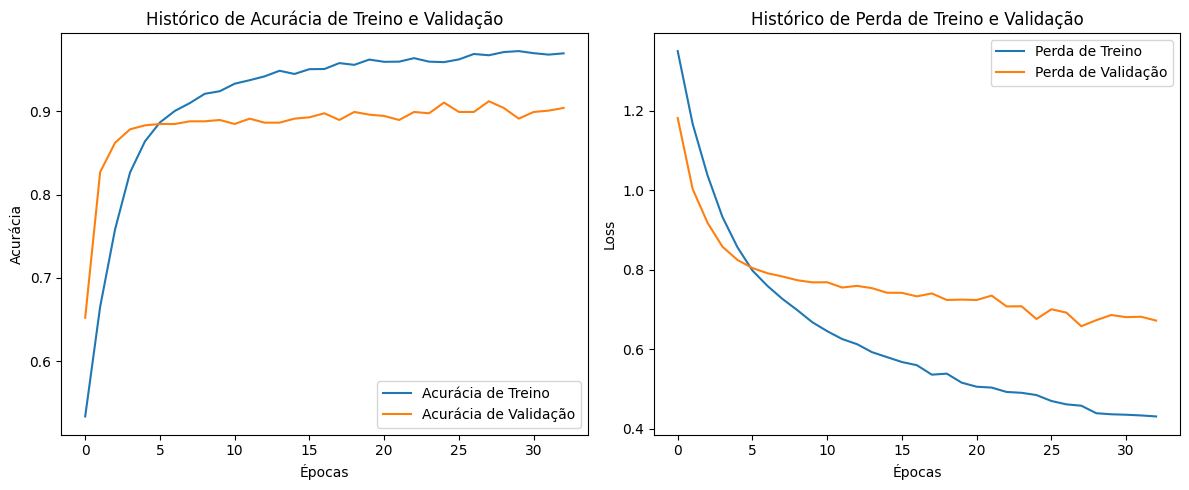

In [12]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Acurácia de Treino')
plt.plot(history.history['val_accuracy'], label='Acurácia de Validação')
plt.title('Histórico de Acurácia de Treino e Validação')
plt.legend()
plt.xlabel('Épocas')
plt.ylabel('Acurácia')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Perda de Treino')
plt.plot(history.history['val_loss'], label='Perda de Validação')
plt.title('Histórico de Perda de Treino e Validação')
plt.legend()
plt.xlabel('Épocas')
plt.ylabel('Loss')

plt.tight_layout()
plt.savefig('Desempenho_DenseNet121.png', bbox_inches='tight', dpi=300)
plt.show()

In [13]:
model.save('modelDenseNet121_Pneumonia.keras')

model_carregado = tf.keras.models.load_model('modelDenseNet121_Pneumonia.keras')

In [14]:
y_pred_prob = model.predict(validation_dataset)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()
y_true = np.concatenate([y.numpy() for x, y in validation_dataset], axis=0).flatten()

relatorio = classification_report(y_true, y_pred, target_names=class_names, digits=4)
print("Relatório de Classificação:\n")
print(relatorio)

20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 300ms/step
Relatório de Classificação:

              precision    recall  f1-score   support

      NORMAL     0.9453    0.8120    0.8736       234
   PNEUMONIA     0.8960    0.9718    0.9323       390

    accuracy                         0.9119       624
   macro avg     0.9206    0.8919    0.9030       624
weighted avg     0.9145    0.9119    0.9103       624



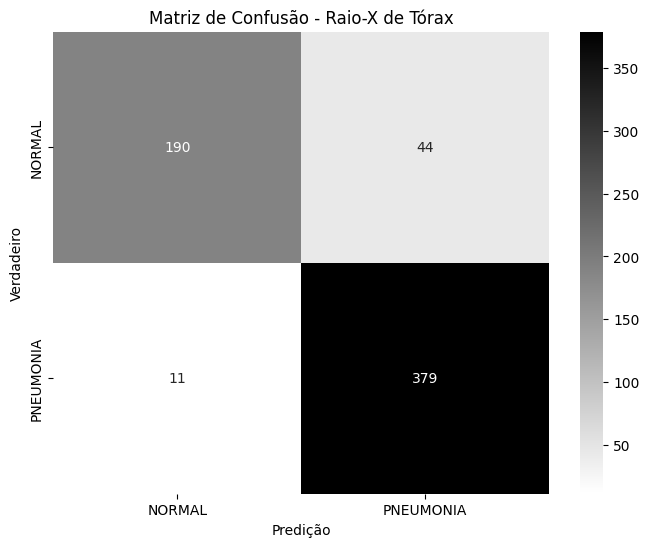

In [15]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='gray_r', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predição')
plt.ylabel('Verdadeiro')
plt.title('Matriz de Confusão - Raio-X de Tórax')
plt.savefig('confusion_matrix_pneumonia.png', bbox_inches='tight', dpi=300)
plt.show()

In [16]:
imagens_normal = []
imagens_pneumonia = []
labels_normal = []
labels_pneumonia = []

for images_batch, labels_batch in validation_dataset:
    for img, lbl in zip(images_batch, labels_batch):
        classe = int(lbl.numpy()[0])
        if classe == 0 and len(imagens_normal) < 3:
            imagens_normal.append(img.numpy())
            labels_normal.append(classe)
        elif classe == 1 and len(imagens_pneumonia) < 3:
            imagens_pneumonia.append(img.numpy())
            labels_pneumonia.append(classe)

    if len(imagens_normal) >= 3 and len(imagens_pneumonia) >= 3:
        break

In [17]:
test_sample = np.array(imagens_normal[:2] + imagens_pneumonia[:2])
real_classes = np.array(labels_normal[:2] + labels_pneumonia[:2])

for images_batch, _ in validation_dataset.take(3):
    background = images_batch.numpy()
    break

pred = model.predict(test_sample)
pred_classes = (pred >= 0.5).astype(int).flatten()

print("Classes Preditas:", pred_classes)
print("Classes Reais:   ", real_classes)

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Classes Preditas: [0 0 1 1]
Classes Reais:    [0 0 1 1]


In [18]:
explainer = shap.GradientExplainer(model, background)
shap_values = explainer.shap_values(test_sample)

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_427
Received: inputs=['Tensor(shape=(4, 224, 224, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_427
Received: inputs=['Tensor(shape=(50, 224, 224, 3))']
  warnings.warn(msg)


Classe prevista: NORMAL | Classe real: NORMAL


<Figure size 600x600 with 0 Axes>

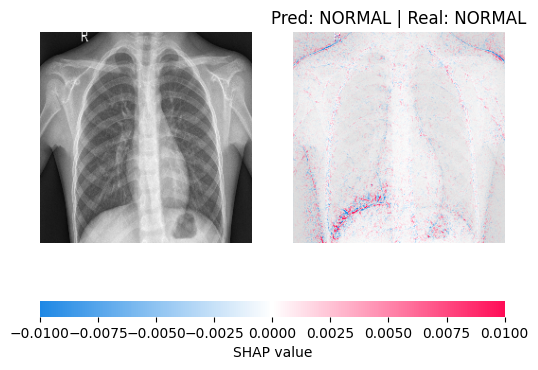

Classe prevista: NORMAL | Classe real: NORMAL


<Figure size 600x600 with 0 Axes>

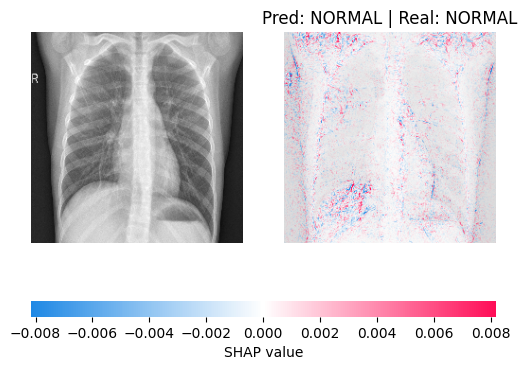

Classe prevista: PNEUMONIA | Classe real: PNEUMONIA


<Figure size 600x600 with 0 Axes>

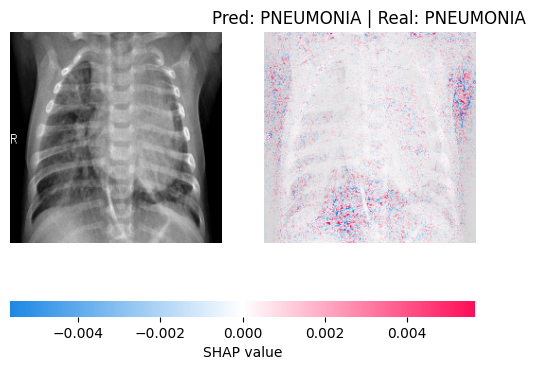

Classe prevista: PNEUMONIA | Classe real: PNEUMONIA


<Figure size 600x600 with 0 Axes>

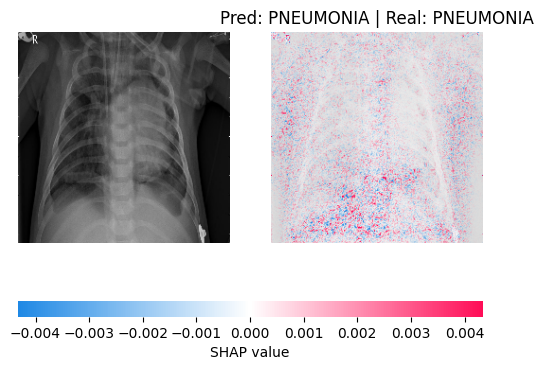

In [19]:
for i in range(len(test_sample)):
    print(f"Classe prevista: {class_names[pred_classes[i]]}" f" | Classe real: {class_names[real_classes[i]]}")

    if isinstance(shap_values, list):
        current_shap = shap_values[0][i]
    else:
        current_shap = shap_values[i, :, :, :, 0] if len(shap_values.shape) == 5 else shap_values[i]

    current_img = test_sample[i]

    plt.figure(figsize=(6, 6))
    shap.image_plot(current_shap, current_img, show=False)

    plt.title(f"Pred: {class_names[pred_classes[i]]} | Real: {class_names[real_classes[i]]}")
    plt.savefig(f"shap_amostra_{i}.png", bbox_inches="tight", dpi=300)
    plt.show()
    plt.close()